# Análise espacial complementar — ambiente 1006

Compara regressão linear com seleção por distância e por correlação no treinamento.
Os mesmos seis alvos, candidatos e timestamps são usados em ambas as estratégias.
A grade e a divisão temporal são herdadas do experimento principal (nove sensores completos),
para preservar o período de avaliação. O mapa usa médias observadas no período completo,
apenas para descrição espacial; não participa da seleção ou do treinamento.

As coordenadas vêm de `code/sensorsWithCoordinates`, confirmado pelo autor.
A divisória e a abertura são aproximações obtidas da planta fornecida; não são levantamento
geométrico de precisão. Os dados do cluster e da reunião da API Smartlab não são combinados
com o QuestDB porque sua convenção temporal ainda precisa ser confirmada.

In [1]:
from pathlib import Path
import ast
import hashlib
import json
import platform

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import sklearn
from scipy.spatial import Delaunay
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "code/sensores.json").is_file()), None)
if ROOT is None:
    raise RuntimeError("Execute dentro do projeto temperatureMonitoring.")
BASE = ROOT / "code/tcc"
OUT = BASE / "results/espacial"
TABLES = OUT / "tabelas"
FIGS = OUT / "figuras"
for p in (OUT, TABLES, FIGS):
    p.mkdir(parents=True, exist_ok=True)

COORD_FILE = ROOT / "code/sensorsWithCoordinates"
DATA_FILE = BASE / "data/processed/temperaturas_1006_5min_completas.csv"
CONFIG_03 = BASE / "results/experimentos/configuracao_execucao.json"
IDS = [48, 887, 891, 86790, 86791, 86793]
KS = [1, 2, 3, 4, 5]

# Geometria aproximada lida da planta, não coordenadas medidas de paredes.
DIV_Y = 5.1
DIV_FIM_X = 5.7
PAREDE_X = 6.2
LIM_X = (0.0, 8.0)
LIM_Y = (0.0, 7.2)
print("Saídas:", OUT)


Saídas: /home/gustavomoura/Documents/temperatureMonitoring/code/tcc/results/espacial


## 1. Coordenadas e matriz experimental
O arquivo de coordenadas é lido como literal Python, sem executar seu conteúdo.

In [2]:
arvore = ast.parse(COORD_FILE.read_text(encoding="utf-8"))
atribuicao = next(x for x in arvore.body if isinstance(x, ast.Assign)
                  and any(isinstance(t, ast.Name) and t.id == "sensor_positions"
                          for t in x.targets))
posicoes = ast.literal_eval(atribuicao.value)
inventario = pd.read_csv(BASE / "data/metadata/sensores.csv")
if not inventario["id_device"].is_unique:
    raise ValueError("IDs duplicados no inventário.")
if set(inventario["nome"]) != set(posicoes):
    raise ValueError("Os nomes do inventário e do cadastro espacial diferem.")
# Sempre usar o cadastro confirmado, mesmo se o CSV exploratório estiver desatualizado.
inventario["x_aprox"] = inventario["nome"].map(lambda nome: posicoes[nome][0])
inventario["y_aprox"] = inventario["nome"].map(lambda nome: posicoes[nome][1])
coords = inventario.set_index("id_device").loc[IDS, ["x_aprox", "y_aprox"]]
if not np.isfinite(coords.to_numpy()).all() or coords.duplicated().any():
    raise ValueError("Coordenadas ausentes ou coincidentes no conjunto experimental.")

dados = pd.read_csv(DATA_FILE, index_col="timestamp")
dados.index = pd.to_datetime(dados.index, utc=True, errors="raise")
dados.columns = dados.columns.astype(int)
dados = dados.sort_index()
config_03 = json.loads(CONFIG_03.read_text())
assert hashlib.sha256(DATA_FILE.read_bytes()).hexdigest() == config_03["sha256_dados"]
assert not dados.index.has_duplicates
assert np.isfinite(dados.to_numpy()).all()
assert len(dados) == config_03["n_treino"] + config_03["n_teste"]
assert set(IDS).issubset(dados.columns)

dados = dados.loc[:, IDS]
corte = config_03["n_treino"]
treino, teste = dados.iloc[:corte].copy(), dados.iloc[corte:].copy()
assert treino.index.max() < teste.index.min()
assert teste.index.min().isoformat() == config_03["inicio_teste_utc"]
assert teste.index.max().isoformat() == config_03["fim_teste_utc"]
inventario.to_csv(TABLES / "inventario_espacial.csv", index=False)
display(coords)
print("Treino:", treino.shape, "Teste:", teste.shape)


,x_aprox,y_aprox
id_device,,
48,8.0,5.6
887,0.0,0.0
891,0.0,4.9
86790,3.0,1.4
86791,5.0,1.4
86793,8.0,0.0


Treino: (9024, 6) Teste: (3868, 6)


## 2. Disponibilidade nas extrações locais

Esta tabela caracteriza os arquivos disponíveis neste projeto, não todo o conteúdo dos servidores.
QuestDB: linhas agregadas por cinco minutos. Smartlab: linhas retornadas pela API, cuja resolução
efetiva e fuso não estão equiparados ao QuestDB. As contagens de linhas não são comparáveis como
cobertura; ausência do CSV selecionado não significa ausência do dispositivo na fonte.

In [3]:
quest = pd.read_csv(BASE / "data/metadata/resumo_questdb_1006.csv").set_index("sensor_id")
ids_inventario = set(inventario.id_device) | set(quest.index)
rotulos = inventario.set_index("id_device")
linhas = []
for sid in sorted(ids_inventario):
    caminho_api = BASE / f"data/raw/smartlab/sensor_{sid}_2026-06-10_2026-07-26.csv"
    api = pd.read_csv(caminho_api) if caminho_api.exists() else None
    linhas.append({
        "sensor_id": sid,
        "regiao_inventario": rotulos.loc[sid, "regiao"] if sid in rotulos.index else "sem coordenadas",
        "coordenadas_confirmadas": sid in rotulos.index,
        "questdb_extracao_principal": sid in quest.index,
        "questdb_janelas_validas": int(quest.loc[sid, "janelas_validas"]) if sid in quest.index else None,
        "smartlab_csv_local": api is not None,
        "smartlab_linhas_retornadas": len(api) if api is not None else None,
        "smartlab_primeiro_timestamp_textual": api.time_interval.min() if api is not None and len(api) else None,
        "smartlab_ultimo_timestamp_textual": api.time_interval.max() if api is not None and len(api) else None,
    })
disponibilidade = pd.DataFrame(linhas)
disponibilidade.to_csv(TABLES / "disponibilidade_fontes_locais.csv", index=False)
display(disponibilidade)


,sensor_id,regiao_inventario,coordenadas_confirmadas,questdb_extracao_principal,questdb_janelas_validas,smartlab_csv_local,smartlab_linhas_retornadas,smartlab_primeiro_timestamp_textual,smartlab_ultimo_timestamp_textual
0,1,sem coordenadas,False,True,12944.0,False,NaN,NaN,NaN
1,48,1006,True,True,12902.0,True,92083.0,2026-06-10T00:00:00,2026-07-25T06:58:00
2,885,Cluster,True,False,NaN,True,97280.0,2026-06-10T00:00:00,2026-07-25T06:58:30
3,887,1006,True,True,12931.0,True,96077.0,2026-06-10T00:00:30,2026-07-25T06:58:00
4,891,1006,True,True,12954.0,True,97318.0,2026-06-10T00:00:00,2026-07-25T06:58:30
5,1025,Reuniao,True,False,NaN,True,96988.0,2026-06-10T00:00:00,2026-07-25T06:58:30
6,86782,sem coordenadas,False,True,12963.0,False,NaN,NaN,NaN
7,86786,Cluster,True,False,NaN,True,96773.0,2026-06-10T00:00:00,2026-07-25T06:58:30
8,86789,sem coordenadas,False,True,12918.0,False,NaN,NaN,NaN
9,86790,1006,True,True,12925.0,True,97309.0,2026-06-10T00:01:00,2026-07-25T06:58:30


## 3. Distância e correlação

Distância euclidiana nas unidades relativas do cadastro. Ordenação por correlação de Pearson
com sinal, em ordem decrescente, calculada apenas no treinamento (mesma regra do notebook 03).
Empates são resolvidos pelo menor ID. Os seis sensores candidatos pertencem ao ambiente 1006;
não são selecionados sensores do cluster através da divisória.

In [4]:
xy = coords.to_numpy(dtype=float)
distancias = pd.DataFrame(np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=2),
                         index=IDS, columns=IDS)
correlacoes = treino.corr()
distancias.to_csv(TABLES / "distancias_relativas.csv", index_label="sensor_alvo")
correlacoes.to_csv(TABLES / "correlacoes_treinamento.csv", index_label="sensor_alvo")
rankings = []
for alvo in IDS:
    candidatos = sorted(s for s in IDS if s != alvo)
    if correlacoes.loc[candidatos, alvo].isna().any():
        raise ValueError("Correlação indefinida no treinamento.")
    por_distancia = sorted(candidatos, key=lambda s: (distancias.loc[alvo, s], s))
    por_correlacao = sorted(candidatos, key=lambda s: (-correlacoes.loc[s, alvo], s))
    for estrategia, ordem in [("Proximidade", por_distancia), ("Correlacao", por_correlacao)]:
        for posicao, sid in enumerate(ordem, 1):
            rankings.append({"sensor_alvo": alvo, "estrategia": estrategia,
                             "ordem": posicao, "sensor_entrada": sid,
                             "distancia_relativa": distancias.loc[alvo, sid],
                             "correlacao_treino": correlacoes.loc[sid, alvo]})
rankings = pd.DataFrame(rankings)
rankings.to_csv(TABLES / "rankings_entradas.csv", index=False)
display(rankings[rankings.ordem == 1])


,sensor_alvo,estrategia,ordem,sensor_entrada,distancia_relativa,correlacao_treino
0,48,Proximidade,1,86791,5.161395,0.911666
5,48,Correlacao,1,86790,6.529931,0.958448
10,887,Proximidade,1,86790,3.310589,0.908847
15,887,Correlacao,1,86793,8.000000,0.944702
20,891,Proximidade,1,86790,4.609772,0.922035
25,891,Correlacao,1,48,8.030567,0.948191
30,86790,Proximidade,1,86791,2.000000,0.906582
35,86790,Correlacao,1,48,6.529931,0.958448
40,86791,Proximidade,1,86790,2.000000,0.906582
45,86791,Correlacao,1,48,5.161395,0.911666


## 4. Regressão linear com as duas regras de seleção
Avaliação descritiva dos valores predefinidos de k; o teste não é usado para criar o ranking ou ajustar parâmetros.

In [5]:
resultados, previsoes = [], []
for alvo in IDS:
    for estrategia in ["Proximidade", "Correlacao"]:
        ordem = rankings[(rankings.sensor_alvo == alvo) &
                         (rankings.estrategia == estrategia)].sort_values("ordem").sensor_entrada.tolist()
        for k in KS:
            entradas = ordem[:k]
            modelo = LinearRegression().fit(treino[entradas], treino[alvo])
            pred = modelo.predict(teste[entradas])
            resultados.append({
                "sensor_alvo": alvo, "estrategia": estrategia, "k": k,
                "sensores_entrada": json.dumps([int(x) for x in entradas]),
                "n_treino": len(treino), "n_teste": len(teste),
                "MAE": mean_absolute_error(teste[alvo], pred),
                "RMSE": np.sqrt(mean_squared_error(teste[alvo], pred)),
                "R2": r2_score(teste[alvo], pred),
            })
            previsoes.append(pd.DataFrame({"timestamp": teste.index, "sensor_alvo": alvo,
                                            "estrategia": estrategia, "k": k,
                                            "real": teste[alvo].to_numpy(), "estimada": pred}))
resultados = pd.DataFrame(resultados)
previsoes = pd.concat(previsoes, ignore_index=True)
resumo = resultados.groupby(["estrategia", "k"], as_index=False).agg(
    MAE_medio=("MAE", "mean"), RMSE_medio=("RMSE", "mean"), R2_medio=("R2", "mean"),
    MAE_desvio_entre_alvos=("MAE", "std"))

# Com todas as cinco entradas, muda apenas a ordem das colunas.
for metrica in ["MAE", "RMSE", "R2"]:
    completos = resultados[resultados.k == 5].pivot(index="sensor_alvo", columns="estrategia", values=metrica)
    np.testing.assert_allclose(completos.Proximidade, completos.Correlacao, rtol=1e-7, atol=1e-9)
assert len(resultados) == 60
assert len(previsoes) == 60 * len(teste)
resultados.to_csv(TABLES / "metricas_espaciais_por_alvo.csv", index=False)
resumo.to_csv(TABLES / "resumo_selecao_espacial.csv", index=False)
previsoes.to_csv(OUT / "previsoes_espaciais.csv.gz", index=False, compression="gzip")
display(resumo.round(6))
print("Conferência k=5 concluída; 60 avaliações e", len(previsoes), "previsões.")


,estrategia,k,MAE_medio,RMSE_medio,R2_medio,MAE_desvio_entre_alvos
0,Correlacao,1,0.315421,0.416680,0.807617,0.072809
1,Correlacao,2,0.297927,0.379200,0.827754,0.072764
2,Correlacao,3,0.285071,0.365043,0.834435,0.082135
3,Correlacao,4,0.275618,0.352851,0.837987,0.096361
4,Correlacao,5,0.266363,0.345774,0.853502,0.088498
5,Proximidade,1,0.389956,0.487937,0.722009,0.098289
6,Proximidade,2,0.373792,0.458485,0.748707,0.073292
7,Proximidade,3,0.367376,0.459094,0.755336,0.089249
8,Proximidade,4,0.295380,0.374365,0.828106,0.081296
9,Proximidade,5,0.266363,0.345774,0.853502,0.088498


Conferência k=5 concluída; 60 avaliações e 232080 previsões.


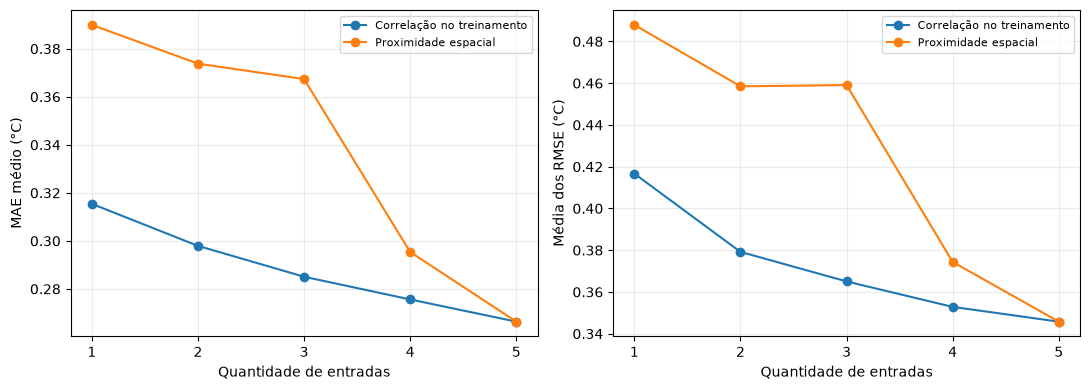

In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
for estrategia, grupo in resumo.groupby("estrategia"):
    nome = {"Correlacao": "Correlação no treinamento", "Proximidade": "Proximidade espacial"}[estrategia]
    eixos[0].plot(grupo.k, grupo.MAE_medio, marker="o", label=nome)
    eixos[1].plot(grupo.k, grupo.RMSE_medio, marker="o", label=nome)
for ax, metrica in zip(eixos, ["MAE médio (°C)", "Média dos RMSE (°C)"]):
    ax.set(xlabel="Quantidade de entradas", ylabel=metrica, xticks=KS)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
for ext in ["pdf", "png"]:
    fig.savefig(FIGS / f"comparacao_selecao_espacial.{ext}", dpi=240, bbox_inches="tight")
plt.show()


## 5. Mapa de temperaturas médias observadas e interpolação ilustrativa

As médias abaixo usam as mesmas 12.892 janelas para os seis sensores. O painel esquerdo mostra
apenas valores observados; o direito mostra IDW (potência 2, todas as seis entradas). O mapa não
é um modelo validado do campo térmico, nem estima a temperatura instantânea da sala. A IDW é
apenas visualização complementar e não participa das métricas de regressão.

A interpolação é restrita ao envoltório convexo dos seis pontos e ao espaço fora do cluster.
A divisória horizontal e a parede vertical são desenhadas tracejadas porque a geometria foi
inferida da planta. O intervalo entre x=5,7 e x=6,2 representa a abertura aproximada. Cluster
e região de acesso permanecem sem preenchimento quando não cobertos pelo domínio. Não se
interpola entre os sensores dos dois lados da divisória. Os sensores cadastrados na reunião
são mostrados como referência de posição, sem atribuir a eles temperaturas do QuestDB.

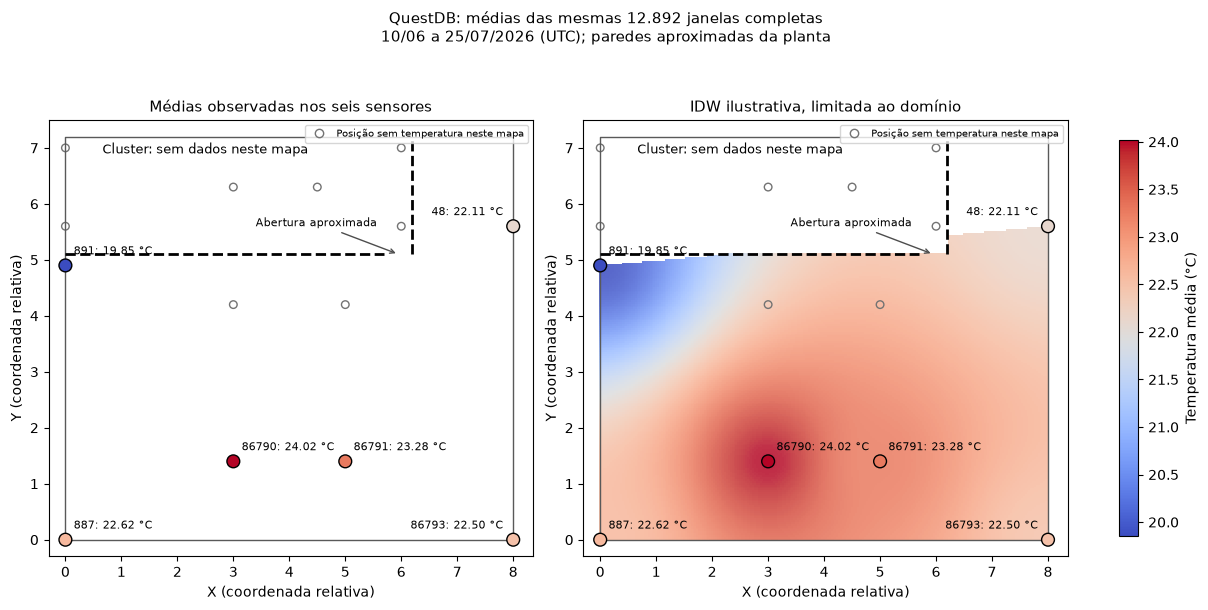

,x_aprox,y_aprox,media_c,n_janelas
id_device,,,,
48,8.0,5.6,22.114,12892
887,0.0,0.0,22.618,12892
891,0.0,4.9,19.850,12892
86790,3.0,1.4,24.019,12892
86791,5.0,1.4,23.276,12892
86793,8.0,0.0,22.497,12892


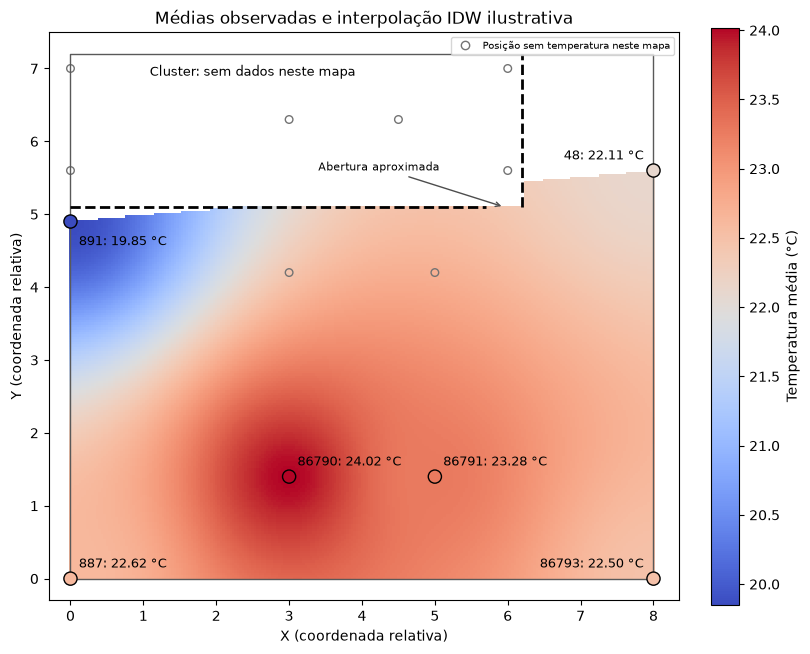

In [7]:
def desenhar_planta(ax):
    ax.plot([0, 8, 8, 0, 0], [0, 0, 7.2, 7.2, 0], color="0.35", lw=1)
    ax.plot([0, DIV_FIM_X], [DIV_Y, DIV_Y], "k--", lw=2)
    ax.plot([PAREDE_X, PAREDE_X], [DIV_Y, LIM_Y[1]], "k--", lw=2)
    ax.text(2.5, 6.9, "Cluster: sem dados neste mapa", ha="center", fontsize=9)
    ax.annotate("Abertura aproximada", xy=(5.95, DIV_Y), xytext=(3.4, 5.6),
                fontsize=8, arrowprops={"arrowstyle": "->", "color": "0.3"})
    outros = inventario[~inventario.id_device.isin(IDS)]
    ax.scatter(outros.x_aprox, outros.y_aprox, facecolors="none", edgecolors="0.45", s=30)
    ax.set(xlim=(-0.3, 8.35), ylim=(-0.3, 7.5),
           xlabel="X (coordenada relativa)", ylabel="Y (coordenada relativa)")
    ax.set_aspect("equal")
    ax.legend(handles=[Line2D([], [], marker="o", linestyle="none", markerfacecolor="none",
                            markeredgecolor="0.45", label="Posição sem temperatura neste mapa")],
              loc="upper right", fontsize=7)

medias = dados.mean().reindex(IDS)
mapa_valores = coords.copy()
mapa_valores["media_c"] = medias
mapa_valores["n_janelas"] = len(dados)
mapa_valores.to_csv(TABLES / "temperaturas_mapa.csv", index_label="sensor_id")
gx, gy = np.meshgrid(np.linspace(0, 8, 241), np.linspace(0, 7.2, 217))
pontos = np.column_stack([gx.ravel(), gy.ravel()])
d = np.linalg.norm(pontos[:, None, :] - xy[None, :, :], axis=2)
# Distância nula: atribuição explícita do valor observado.
pesos = 1 / np.maximum(d, 1e-12)**2
valores = (pesos @ medias.to_numpy()) / pesos.sum(axis=1)
for j in range(len(IDS)):
    valores[d[:, j] < 1e-10] = medias.iloc[j]
no_envoltorio = Delaunay(xy).find_simplex(pontos) >= 0
fora_cluster = ~((pontos[:, 0] <= PAREDE_X) & (pontos[:, 1] > DIV_Y))
mascara = (no_envoltorio & fora_cluster).reshape(gx.shape)
campo = np.where(mascara, valores.reshape(gx.shape), np.nan)
assert not np.isfinite(campo[(gx <= PAREDE_X) & (gy > DIV_Y)]).any()
assert np.nanmin(campo) >= medias.min() - 1e-10
assert np.nanmax(campo) <= medias.max() + 1e-10
np.savez_compressed(OUT / "grade_idw_media.npz", x=gx, y=gy, temperatura=campo, dominio=mascara)

fig, eixos = plt.subplots(1, 2, figsize=(12, 6.2), layout="constrained")
vmin, vmax = medias.min(), medias.max()
for i, ax in enumerate(eixos):
    if i == 1:
        ax.pcolormesh(gx, gy, np.ma.masked_invalid(campo), cmap="coolwarm",
                      vmin=vmin, vmax=vmax, shading="auto", rasterized=True, alpha=0.85)
    desenhar_planta(ax)
    pontos_plot = ax.scatter(coords.x_aprox, coords.y_aprox, c=medias, cmap="coolwarm",
                             vmin=vmin, vmax=vmax, s=85, edgecolors="black", zorder=4)
    for sid, row in mapa_valores.iterrows():
        dx = -7 if row.x_aprox >= 7.9 else 6
        ax.annotate(f"{sid}: {row.media_c:.2f} °C", (row.x_aprox, row.y_aprox),
                    xytext=(dx, 8), textcoords="offset points",
                    ha="right" if dx < 0 else "left", fontsize=8, zorder=5)
    ax.set_title(["Médias observadas nos seis sensores", "IDW ilustrativa, limitada ao domínio"][i], fontsize=11)
fig.colorbar(pontos_plot, ax=eixos, shrink=0.7, label="Temperatura média (°C)")
fig.suptitle("QuestDB: médias das mesmas 12.892 janelas completas\n"
             "10/06 a 25/07/2026 (UTC); paredes aproximadas da planta", fontsize=11)
for ext in ["pdf", "png"]:
    fig.savefig(FIGS / f"mapa_termico_1006.{ext}", dpi=240, bbox_inches="tight")
plt.show()
display(mapa_valores.round(3))

# Versão em painel único para legibilidade na monografia.
fig, ax = plt.subplots(figsize=(8, 7.3), layout="constrained")
im = ax.pcolormesh(gx, gy, np.ma.masked_invalid(campo), cmap="coolwarm",
                   vmin=vmin, vmax=vmax, shading="auto", rasterized=True)
desenhar_planta(ax)
ax.scatter(coords.x_aprox, coords.y_aprox, c=medias, cmap="coolwarm", vmin=vmin,
           vmax=vmax, s=90, edgecolors="black", zorder=4)
for sid, row in mapa_valores.iterrows():
    dx = -7 if row.x_aprox >= 7.9 else 6
    ax.annotate(f"{sid}: {row.media_c:.2f} °C", (row.x_aprox, row.y_aprox),
                xytext=(dx, -17 if sid == 891 else 8), textcoords="offset points",
                ha="right" if dx < 0 else "left", fontsize=9, zorder=5)
ax.set_title("Médias observadas e interpolação IDW ilustrativa", fontsize=12)
fig.colorbar(im, ax=ax, shrink=0.8, label="Temperatura média (°C)")
for ext in ["pdf", "png"]:
    fig.savefig(FIGS / f"mapa_termico_1006_painel.{ext}", dpi=240, bbox_inches="tight")
plt.show()


## 6. Registro da execução e limites
Não interpretar o melhor k no teste como uma escolha validada independentemente. Não comparar os erros médios de seis alvos com os de nove alvos como se fossem a mesma avaliação.

In [8]:
config = {
    "executado_em_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "fonte_temperaturas": "QuestDB; mesma matriz de casos completos do notebook 03",
    "sha256_dados": hashlib.sha256(DATA_FILE.read_bytes()).hexdigest(),
    "sha256_coordenadas": hashlib.sha256(COORD_FILE.read_bytes()).hexdigest(),
    "ids": IDS, "k": KS, "n_treino": len(treino), "n_teste": len(teste),
    "inicio_treino_utc": treino.index.min().isoformat(),
    "fim_treino_utc": treino.index.max().isoformat(),
    "inicio_teste_utc": teste.index.min().isoformat(),
    "fim_teste_utc": teste.index.max().isoformat(),
    "parametros_modelo": LinearRegression().get_params(),
    "ordenamento_correlacao": "Pearson decrescente com sinal, somente treinamento; desempate ID",
    "ordenamento_distancia": "Euclidiana crescente; desempate ID; coordenadas relativas",
    "mapa": {"estatistica": "média por sensor nas mesmas 12892 janelas completas do período",
             "idw_potencia": 2, "dominio": "envoltório convexo dos seis sensores, excluído cluster",
             "validacao_campo_termico": False,
             "divisoria_y_aprox": DIV_Y, "divisoria_fim_x_aprox": DIV_FIM_X,
             "parede_vertical_x_aprox": PAREDE_X, "origem_geometria": "planta fornecida pelo autor"},
    "versoes": {"python": platform.python_version(), "pandas": pd.__version__,
                "numpy": np.__version__, "scikit_learn": sklearn.__version__},
}
(OUT / "configuracao_espacial.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")
print("Execução concluída; tabelas, previsões, figuras e configuração em", OUT)


Execução concluída; tabelas, previsões, figuras e configuração em /home/gustavomoura/Documents/temperatureMonitoring/code/tcc/results/espacial
